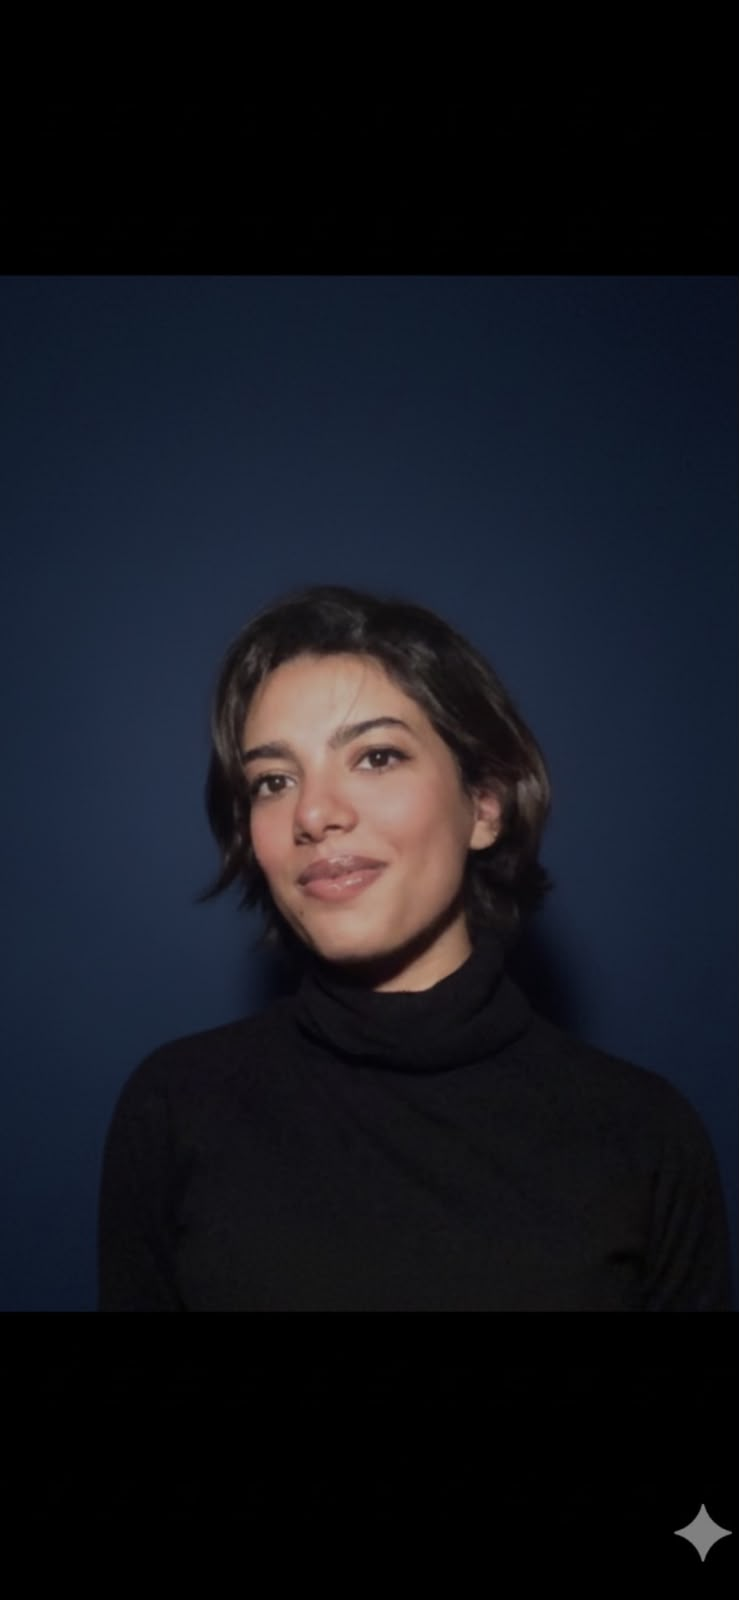

# Partie B — Exploration de 29 algorithmes de Machine Learning

**Variante distincte de la Partie A**, suivant les mêmes 29 rubriques et le même enchaînement de consignes. Les expériences utilisent d'autres jeux de données et des choix de paramètres différents.

- **Régression :** Diabetes, données réelles de scikit-learn (442 patients, 10 caractéristiques).
- **Classification :** Breast Cancer Wisconsin (569 observations, 30 caractéristiques) — exercice pédagogique, non diagnostic.
- **Clustering :** Wine (178 observations, 13 caractéristiques), avec projection ACP.
- **Réduction de dimension :** Digits (chiffres manuscrits, 64 caractéristiques) — autre jeu que Wine.
- **Renforcement :** Taxi-v3 de Gymnasium et bandit simulé à quatre bras.

**Exécutez les cellules dans l'ordre sur Google Colab.** Les jeux de données intégrés à scikit-learn sont publics et réels ; les bandits et environnements Gymnasium sont des simulations, et non des données observées du monde réel.

Sources : [scikit-learn datasets](https://scikit-learn.org/stable/datasets/real_world.html), [Gymnasium Taxi](https://gymnasium.farama.org/environments/toy_text/taxi/).

# Travail demandé — Partie B (variante)

**Organisation :** binôme · **Public :** L3/Master · **Objectif :** savoir décrire, illustrer, situer et expérimenter **29 algorithmes** sur un second ensemble de cas.

Chaque algorithme doit faire l'objet de **quatre réponses** : présentation scientifique, schéma explicatif original, contexte d'utilisation et analyse de l'expérience. Les réponses ne sont pas fournies dans ce notebook : les codes servent de point de départ.

**Différence avec la Partie A :** nouveaux jeux de données (Diabetes, Breast Cancer, Wine et Digits), paramètres alternatifs, environnement Taxi et questions spécifiques sous chaque titre. Les 29 algorithmes et la structure générale restent identiques.

## Partie A — Questions communes à traiter pour chaque algorithme (1 à 29)

**Q1 — Présentation (8 à 12 lignes).** Donner le type de tâche, l'intuition, les étapes d'apprentissage, une formule essentielle et la **définition de tous ses symboles**. Distinguer paramètres appris et hyperparamètres. Donner deux atouts et deux limites.

**Q2 — Schéma original.** Dessiner un organigramme ou une figure scientifique montrant le chemin des données et le mécanisme de l'algorithme. Ajouter une légende et une explication du schéma. Indiquer la source si une figure extérieure est adaptée.

**Q3 — Contextes d'utilisation.** Décrire deux applications concrètes (au moins une en finance, gestion, logistique ou commerce international), les conditions nécessaires, un cas où la méthode est inappropriée et les métriques adaptées.

**Q4 — Analyse expérimentale.** Exécuter la cellule Python, citer la taille des données et les paramètres, interpréter les métriques et modifier **au moins un hyperparamètre** pour discuter son effet. Ne pas inventer de résultats.

**À ajouter par les étudiants sous chaque algorithme :** « Présentation », « Schéma explicatif », « Contexte d'utilisation », « Analyse et variation d'hyperparamètre ».

## Partie B — Validation finale sur des données publiques

**Q5. Provenance.** Choisir un jeu de données public distinct du cas de démonstration pour chaque famille de méthodes ; préciser la source officielle, l'URL, la date, les dimensions et la cible éventuelle. Une même base peut servir à plusieurs modèles compatibles.

**Q6. Prétraitement.** Identifier les variables manquantes, l'encodage, la standardisation et les éventuelles fuites de données. Ajuster les transformations sur l'entraînement uniquement quand il s'agit de prédire.

**Q7. Essais.** Tester tous les algorithmes adaptés aux données et à la tâche, avec un modèle de référence et un modèle avancé par famille. Séparer train/test (chronologiquement pour les séries temporelles). L'ACP, t-SNE et UMAP sont des outils exploratoires, pas des prédicteurs supervisés.

**Q8. Évaluation et analyse.** Comparer MAE/RMSE/R² (régression), F1/ROC-AUC/PR-AUC (classification, selon le déséquilibre), silhouette/stabilité (clustering), préservation locale (projections) et taux de réussite/récompense (renforcement).

**Note importante :** les bandits et Q-learning/SARSA nécessitent des environnements d'interaction. La démonstration DQN présente la cible de Bellman, **pas** un entraînement d'un réseau neuronal. Un DQN complet est un prolongement facultatif.

**Sources possibles :** [UCI](https://archive.ics.uci.edu/), [OpenML](https://www.openml.org/), [UN Comtrade](https://comtradeplus.un.org/), [Banque mondiale](https://data.worldbank.org/).

## Partie C — Restitution et barème

**Livrables :** (1) notebook complété pour les 29 algorithmes, (2) figures originales et paramètres expliqués, (3) expériences sur données publiques complémentaires, (4) rapport de synthèse de 5 à 8 pages, (5) soutenance en binôme.

**Barème /20 :** rigueur des présentations (5), qualité des 29 schémas (4), pertinence des cas d'usage (3), validité des expérimentations (5), reproductibilité et restitution (3).

**Intégrité :** ne pas confondre simulation et données observées ; citer les sources ; aucune valeur de performance ne doit être inventée ; justifier les changements d'hyperparamètres.

---
## Expérimentations Python de la Partie B

In [ ]:
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [ ]:
# Jeux publics de scikit-learn : pas de téléchargement ni de compte requis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, silhouette_score, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
GRAINE = 42

jeu_reg = load_diabetes()
X_reg, y_reg = jeu_reg.data, jeu_reg.target
jeu_cls = load_breast_cancer()
X_cls, y_cls = jeu_cls.data, jeu_cls.target
jeu_groupes = load_wine()
X_clu = PCA(n_components=2, random_state=GRAINE).fit_transform(StandardScaler().fit_transform(jeu_groupes.data))
jeu_images = load_digits()
X_images = StandardScaler().fit_transform(jeu_images.data)
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg,y_reg,test_size=.25,random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls,y_cls,test_size=.25,stratify=y_cls,random_state=GRAINE)
print('Diabetes',X_reg.shape,'Breast cancer',X_cls.shape,'Wine',X_clu.shape,'Digits',X_images.shape)

Diabetes (442, 10) Breast cancer (569, 30) Wine (178, 2) Digits (1797, 64)


## Q0 — Affichage et visualisation des données disponibles
Les jeux intégrés `load_diabetes`, `load_breast_cancer`, `load_wine` et `load_digits` contiennent des observations publiques réelles et ne sont pas des données synthétiques créées aléatoirement. Les expériences de bandits et de renforcement produisent en revanche des récompenses ou trajectoires simulées.



 Diabetes Dimensions: (442, 10) Aperçu:


,0,1,2,3,4,5,6,7,8,9
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


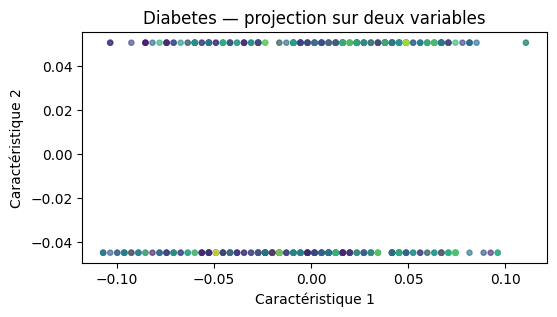


 Breast cancer Dimensions: (569, 30) Aperçu:


,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


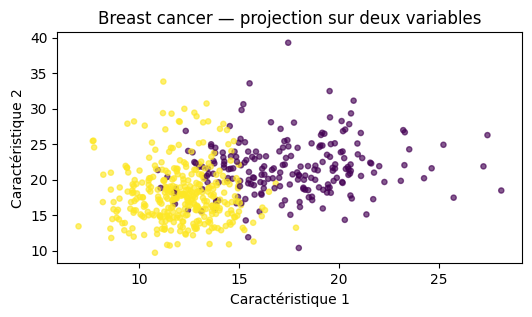


 Wine (projection ACP) Dimensions: (178, 2) Aperçu:


,0,1
0,3.316751,1.443463
1,2.209465,-0.333393
2,2.516740,1.031151
3,3.757066,2.756372
4,1.008908,0.869831


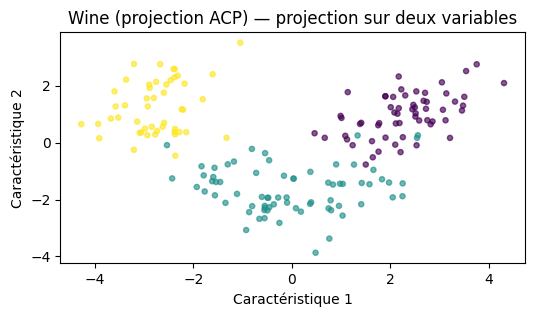


 Digits (standardisé) Dimensions: (1797, 64) Aperçu:


,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
0,0.0,-0.335016,-0.043081,0.274072,-0.664478,-0.844129,-0.409724,-0.125023,-0.059078,-0.624009,...,-0.757436,-0.209785,-0.023596,-0.299081,0.086719,0.208293,-0.366771,-1.146647,-0.505670,-0.196008
1,0.0,-0.335016,-1.094937,0.038648,0.268751,-0.138020,-0.409724,-0.125023,-0.059078,-0.624009,...,-0.757436,-0.209785,-0.023596,-0.299081,-1.089383,-0.249010,0.849632,0.548561,-0.505670,-0.196008
2,0.0,-0.335016,-1.094937,-1.844742,0.735366,1.097673,-0.409724,-0.125023,-0.059078,-0.624009,...,0.259230,-0.209785,-0.023596,-0.299081,-1.089383,-2.078218,-0.164037,1.565686,1.695137,-0.196008
3,0.0,-0.335016,0.377661,0.744919,0.268751,-0.844129,-0.409724,-0.125023,-0.059078,1.879691,...,1.072563,-0.209785,-0.023596,-0.299081,0.282736,0.208293,0.241430,0.379040,-0.505670,-0.196008
4,0.0,-0.335016,-1.094937,-2.551014,-0.197863,-1.020657,-0.409724,-0.125023,-0.059078,-0.624009,...,-0.757436,-0.209785,-0.023596,-0.299081,-1.089383,-2.306869,0.849632,-0.468564,-0.505670,-0.196008


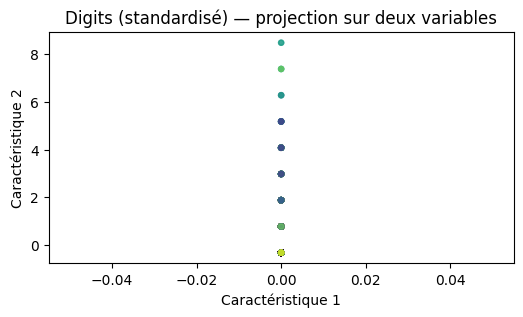

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
for titre, X, y in [('Diabetes', X_reg, y_reg), ('Breast cancer', X_cls, y_cls), ('Wine (projection ACP)', X_clu, jeu_groupes.target), ('Digits (standardisé)', X_images, jeu_images.target)]:
    df = pd.DataFrame(X)
    print('\n', titre, 'Dimensions:', df.shape, 'Aperçu:')
    display(df.head())
    fig, ax = plt.subplots(figsize=(6,3))
    ax.scatter(df.iloc[:,0], df.iloc[:,1], c=y, s=14, alpha=.65, cmap='viridis')
    ax.set(xlabel='Caractéristique 1', ylabel='Caractéristique 2', title=titre + ' — projection sur deux variables')
    plt.show()


### Présentation
**Régression linéaire (Linear regression)** — Famille : **régression**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de régression.
2. Intuition : moindres carrés.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `y = β₀ + Σ βⱼxⱼ`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Simple, interprétable.
11. Limites : Sensible aux valeurs extrêmes, aux relations non linéaires.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** prévision des ventes.
- **Autre application :** estimation des dépenses de santé.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** MAE, RMSE, R².

**Réponse à la question ciblée :** Les relations médicales peuvent être non linéaires, avec interactions et seuils.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **paramètres par défaut ou paramètres définis dans la cellule**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


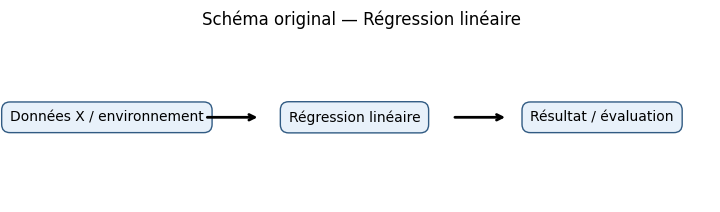

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Régression linéaire'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Régression linéaire', fontsize=12)
plt.show()


In [ ]:
from sklearn.linear_model import LinearRegression
modele=LinearRegression().fit(Xr_ent,yr_ent)
pred=modele.predict(Xr_test)
print('RMSE:',mean_squared_error(yr_test,pred)**.5,'R²:',r2_score(yr_test,pred))

RMSE: 53.369566710321955 R²: 0.4849058889476756


### Présentation
**Ridge (Ridge regression)** — Famille : **régression**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de régression.
2. Intuition : minimisation de l’erreur avec pénalité L2.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `Σ(yᵢ−ŷᵢ)² + αΣβⱼ²`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Stabilise les coefficients, gère la colinéarité.
11. Limites : Ne sélectionne pas exactement les variables, nécessite un réglage de α.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** prévision du chiffre d’affaires.
- **Autre application :** prévision de consommation.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** MAE, RMSE, R².

**Réponse à la question ciblée :** Une pénalité L2 très forte rapproche les coefficients de zéro et augmente le biais.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **alpha**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


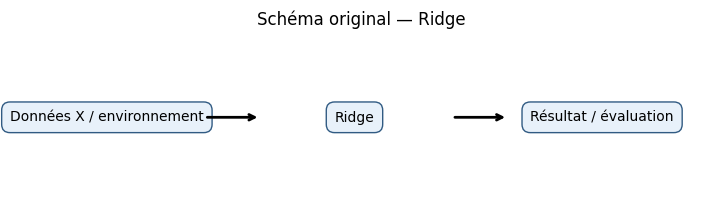

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Ridge'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Ridge', fontsize=12)
plt.show()


In [ ]:
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),Ridge(alpha=25.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.49082128021844


### Présentation
**Lasso (Lasso regression)** — Famille : **régression**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de régression.
2. Intuition : minimisation avec pénalité L1.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `Σ(yᵢ−ŷᵢ)² + αΣ|βⱼ|`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Sélectionne des variables, facilite l’interprétation.
11. Limites : Instable entre variables corrélées, sensible au choix de α.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** sélection de facteurs de risque de crédit.
- **Autre application :** prévision de demande.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** MAE, RMSE, R².

**Réponse à la question ciblée :** La pénalité L1 produit des coefficients exactement nuls, réalisant une sélection.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **alpha**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


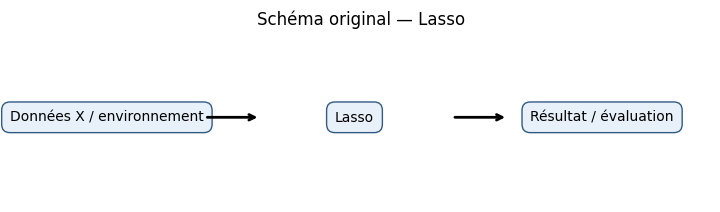

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Lasso'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Lasso', fontsize=12)
plt.show()


In [ ]:
from sklearn.linear_model import Lasso
modele=make_pipeline(StandardScaler(),Lasso(alpha=3.,max_iter=15000)).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.5013056660042327


### Présentation
**Régression polynomiale (Polynomial regression)** — Famille : **régression**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de régression.
2. Intuition : création de puissances et interactions puis régression.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `ŷ = β₀ + β₁x + β₂x² + …`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Capture des courbures, reste explicable.
11. Limites : Surapprentissage, explosion des variables.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** courbe prix-demande.
- **Autre application :** croissance biologique.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** MAE, RMSE, R².

**Réponse à la question ciblée :** Le nombre de termes augmente rapidement avec le degré et le nombre de variables.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **alpha, degree**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


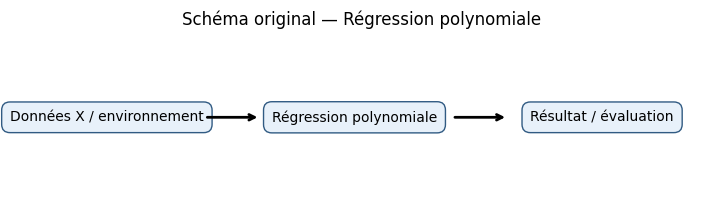

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Régression polynomiale'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Régression polynomiale', fontsize=12)
plt.show()


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),PolynomialFeatures(degree=2,include_bias=False),Ridge(alpha=60.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.24579873763898


### Présentation
**Arbre de régression (Decision tree regression)** — Famille : **régression**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de régression.
2. Intuition : partition récursive minimisant la variance.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `min Σ_feuilles Σᵢ∈feuille(yᵢ−ȳ_feuille)²`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Non linéaire, interprétable.
11. Limites : Instable, surapprentissage.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** prévision de panier moyen.
- **Autre application :** estimation de consommation.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** MAE, RMSE, R².

**Réponse à la question ciblée :** Limiter profondeur et taille des feuilles réduit la variance et le surapprentissage.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **max_depth, random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


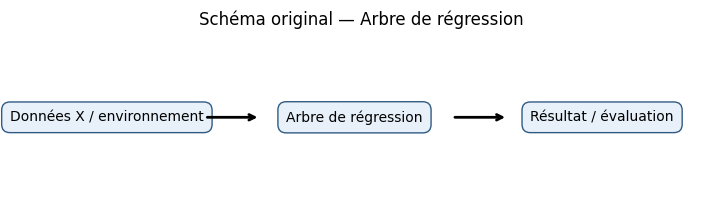

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Arbre de régression'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Arbre de régression', fontsize=12)
plt.show()


In [ ]:
from sklearn.tree import DecisionTreeRegressor
modele=DecisionTreeRegressor(max_depth=3,min_samples_leaf=8,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.4314003646672102


### Présentation
**Forêt aléatoire — régression (Random forest regression)** — Famille : **régression**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de régression.
2. Intuition : moyenne d’arbres entraînés sur bootstrap.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `ŷ = (1/T)Σₜ fₜ(x)`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Robuste, modélise interactions.
11. Limites : Moins interprétable, coûteuse.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** prévision des ventes.
- **Autre application :** estimation immobilière.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** MAE, RMSE, R².

**Réponse à la question ciblée :** Le bootstrap échantillonne avec remise; moyenner les arbres réduit leur variance.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **n_estimators, random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


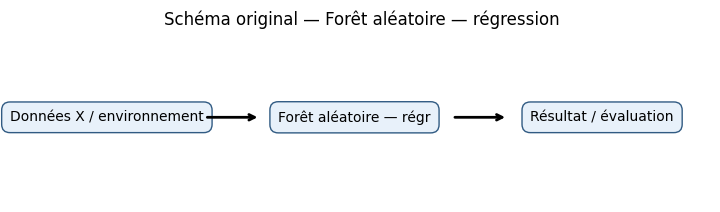

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Forêt aléatoire — régr'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Forêt aléatoire — régression', fontsize=12)
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestRegressor
modele=RandomForestRegressor(n_estimators=120,min_samples_leaf=4,random_state=GRAINE,n_jobs=-1).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 42.58294190565993


### Présentation
**Gradient Boosting — régression (Gradient boosting regression)** — Famille : **régression**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de régression.
2. Intuition : arbres successifs corrigeant les résidus.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `Fₘ(x)=Fₘ₋₁(x)+ηhₘ(x)`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Précis, flexible.
11. Limites : Réglage délicat, entraînement séquentiel.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** prévision de demande.
- **Autre application :** estimation du coût logistique.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** MAE, RMSE, R².

**Réponse à la question ciblée :** Les arbres sont séquentiels car chacun apprend à corriger les erreurs du modèle précédent.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


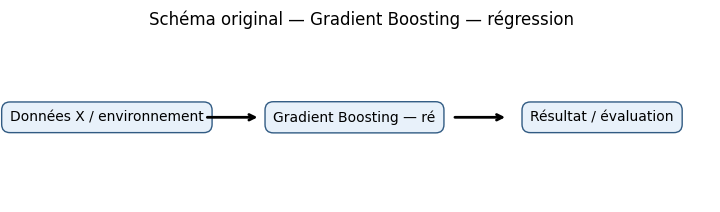

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Gradient Boosting — ré'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Gradient Boosting — régression', fontsize=12)
plt.show()


In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
modele=HistGradientBoostingRegressor(max_iter=110,max_leaf_nodes=12,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('RMSE:',mean_squared_error(yr_test,modele.predict(Xr_test))**.5)

RMSE: 57.12732848789662


### Présentation
**Régression logistique (Logistic regression)** — Famille : **classification**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de classification.
2. Intuition : modélisation de la probabilité par sigmoïde.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `P(y=1|x)=1/(1+exp(−(β₀+βᵀx)))`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Interprétable, rapide.
11. Limites : Frontière linéaire, sensible aux variables mal préparées.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** défaut de crédit.
- **Autre application :** diagnostic médical.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** précision, rappel, F1, ROC-AUC.

**Réponse à la question ciblée :** La probabilité est comparée à un seuil; abaisser le seuil augmente souvent le rappel au détriment de la précision.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **C, random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


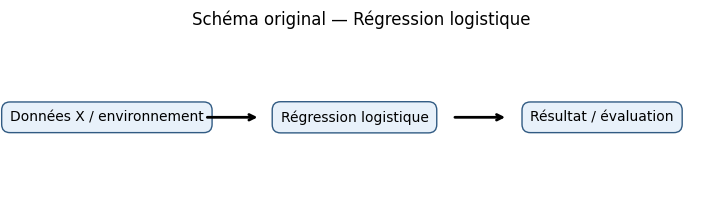

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Régression logistique'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Régression logistique', fontsize=12)
plt.show()


In [ ]:
from sklearn.linear_model import LogisticRegression
modele=make_pipeline(StandardScaler(),LogisticRegression(C=.2,max_iter=1500,random_state=GRAINE)).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


### Présentation
**KNN (K-nearest neighbors)** — Famille : **classification**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de classification.
2. Intuition : vote des k observations les plus proches.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `ŷ = mode{yⱼ : j∈Nₖ(x)}`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Simple, sans entraînement complexe.
11. Limites : Lent en prédiction, sensible à l’échelle.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** segmentation de prospects.
- **Autre application :** reconnaissance de caractères.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** précision, rappel, F1, ROC-AUC.

**Réponse à la question ciblée :** La standardisation évite qu’une variable domine la distance; k petit est instable, k grand lisse.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **n_neighbors**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


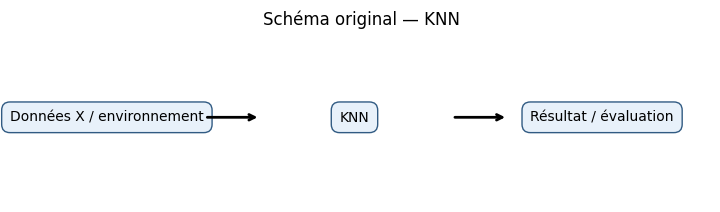

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'KNN'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — KNN', fontsize=12)
plt.show()


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
modele=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=9,weights='distance')).fit(Xc_ent,yc_ent)
print('Exactitude:',accuracy_score(yc_test,modele.predict(Xc_test)))

Exactitude: 0.965034965034965


### Présentation
**Naive Bayes (Naive Bayes)** — Famille : **classification**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de classification.
2. Intuition : théorème de Bayes et indépendance conditionnelle.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `P(y|x) ∝ P(y)∏ⱼP(xⱼ|y)`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Rapide, efficace en grande dimension.
11. Limites : Indépendance souvent irréaliste, probabilités parfois mal calibrées.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** filtrage de courriels commerciaux.
- **Autre application :** classification de documents.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** précision, rappel, F1, ROC-AUC.

**Réponse à la question ciblée :** Il suppose les caractéristiques indépendantes entre elles conditionnellement à la classe.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **paramètres par défaut ou paramètres définis dans la cellule**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


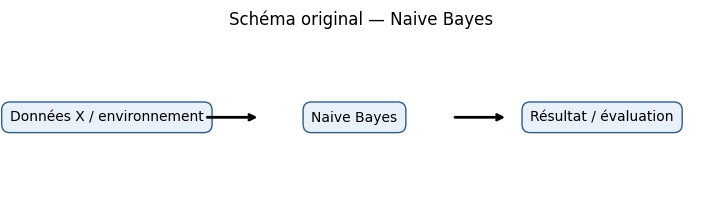

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Naive Bayes'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Naive Bayes', fontsize=12)
plt.show()


In [ ]:
from sklearn.naive_bayes import GaussianNB
modele=GaussianNB(var_smoothing=1e-8).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9621621621621622


### Présentation
**Arbre de décision (Decision tree classifier)** — Famille : **classification**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de classification.
2. Intuition : séparations maximisant la pureté des classes.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `Gini = 1 − Σₖpₖ²`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Lisible, non linéaire.
11. Limites : Instable, surapprentissage.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** scoring commercial.
- **Autre application :** triage médical.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** précision, rappel, F1, ROC-AUC.

**Réponse à la question ciblée :** Choisir la séparation donnant la plus forte baisse pondérée de l’impureté de Gini.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **max_depth, random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


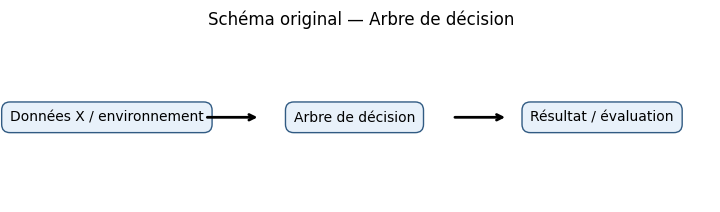

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Arbre de décision'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Arbre de décision', fontsize=12)
plt.show()


In [ ]:
from sklearn.tree import DecisionTreeClassifier
modele=DecisionTreeClassifier(max_depth=3,min_samples_leaf=5,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9560439560439561


### Présentation
**Forêt aléatoire — classification (Random forest classifier)** — Famille : **classification**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de classification.
2. Intuition : vote de plusieurs arbres diversifiés.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `ŷ = mode{f₁(x),…,fₜ(x)}`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Robuste, bonne performance.
11. Limites : Interprétation limitée, ressources nécessaires.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** détection de fraude.
- **Autre application :** classification d’images.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** précision, rappel, F1, ROC-AUC.

**Réponse à la question ciblée :** La diversité des échantillons et des variables diminue l’instabilité d’un arbre isolé.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **max_depth, n_estimators, random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


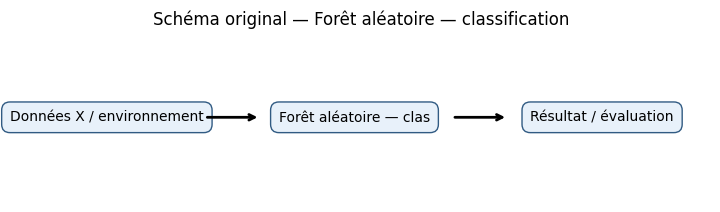

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Forêt aléatoire — clas'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Forêt aléatoire — classification', fontsize=12)
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestClassifier
modele=RandomForestClassifier(n_estimators=110,max_depth=6,random_state=GRAINE,n_jobs=-1).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9613259668508287


### Présentation
**SVM (Support vector machine)** — Famille : **classification**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de classification.
2. Intuition : maximisation de la marge entre classes.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `min ½||w||² + CΣξᵢ`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Efficace en grande dimension, noyaux flexibles.
11. Limites : Coûteux sur grands jeux, réglage sensible.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** détection de fraude.
- **Autre application :** classification de textes.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** précision, rappel, F1, ROC-AUC.

**Réponse à la question ciblée :** Les vecteurs de support définissent la frontière; C élevé pénalise davantage les erreurs.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **C, gamma**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


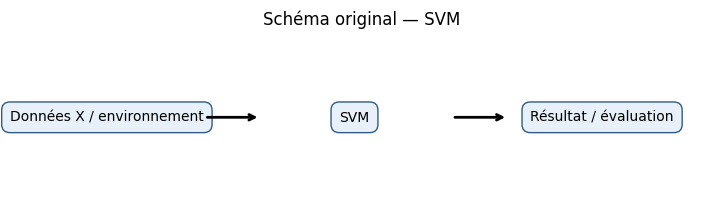

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'SVM'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — SVM', fontsize=12)
plt.show()


In [ ]:
from sklearn.svm import SVC
modele=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=2.,gamma='scale')).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


### Présentation
**Gradient Boosting — classification (Gradient boosting classifier)** — Famille : **classification**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de classification.
2. Intuition : ajout séquentiel de modèles corrigeant la perte.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `Fₘ=Fₘ₋₁+ηhₘ`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Précis, capture les interactions.
11. Limites : Surapprentissage possible, coût de réglage.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** churn clients.
- **Autre application :** détection de maladie.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** précision, rappel, F1, ROC-AUC.

**Réponse à la question ciblée :** Chaque étape ajuste un nouvel arbre aux gradients de la fonction de perte.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


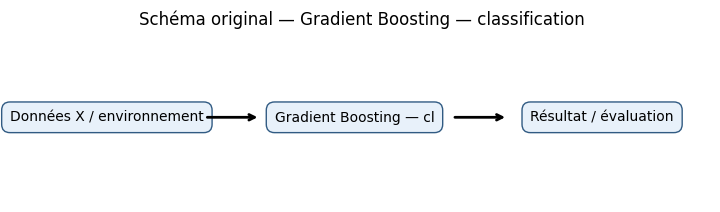

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Gradient Boosting — cl'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Gradient Boosting — classification', fontsize=12)
plt.show()


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
modele=HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=10,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


### Présentation
**AdaBoost (Adaptive boosting)** — Famille : **classification**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de classification.
2. Intuition : pondération accrue des observations mal classées.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `F(x)=sign(Σₜαₜhₜ(x))`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Simple, améliore des classifieurs faibles.
11. Limites : Sensible au bruit, aux valeurs atypiques.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** détection de spam.
- **Autre application :** contrôle qualité.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** précision, rappel, F1, ROC-AUC.

**Réponse à la question ciblée :** Les exemples difficiles reçoivent plus de poids après une erreur de classification.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **learning_rate, n_estimators, random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


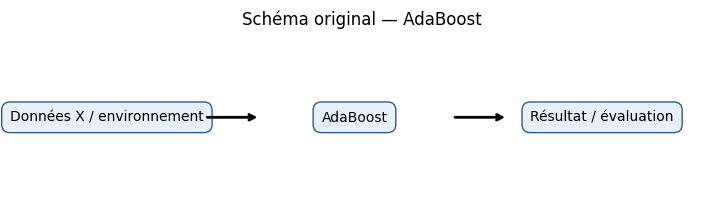

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'AdaBoost'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — AdaBoost', fontsize=12)
plt.show()


In [ ]:
from sklearn.ensemble import AdaBoostClassifier
modele=AdaBoostClassifier(n_estimators=90,learning_rate=.7,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


### Présentation
**XGBoost (Extreme gradient boosting)** — Famille : **classification**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de classification.
2. Intuition : boosting d’arbres avec régularisation.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `objectif = perte + ΣₜΩ(fₜ)`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Performant, régularisé.
11. Limites : Complexité, réglage important.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** risque de crédit.
- **Autre application :** prévision de départ client.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** précision, rappel, F1, ROC-AUC.

**Réponse à la question ciblée :** La régularisation contrôle la complexité; learning_rate réduit la contribution de chaque arbre.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **learning_rate, max_depth, n_estimators, random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


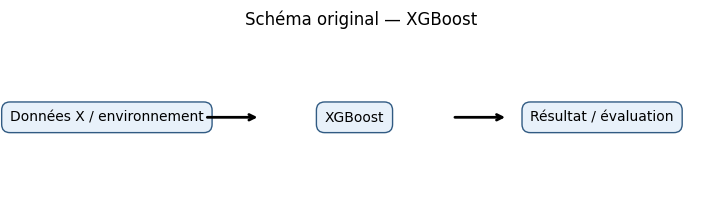

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'XGBoost'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — XGBoost', fontsize=12)
plt.show()


In [ ]:
from xgboost import XGBClassifier
modele=XGBClassifier(n_estimators=100,max_depth=2,learning_rate=.09,random_state=GRAINE,eval_metric='logloss').fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.978021978021978


### Présentation
**K-means (K-means clustering)** — Famille : **clustering**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de clustering.
2. Intuition : affectation au centroïde le plus proche puis mise à jour.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `min Σᵢ||xᵢ−μ_{cᵢ}||²`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Rapide, simple.
11. Limites : Impose k, sensible aux formes non sphériques.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** segmentation clients.
- **Autre application :** regroupement de vins.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** silhouette, stabilité et interprétation.

**Réponse à la question ciblée :** Chaque vin rejoint le centroïde le plus proche; chaque centroïde devient la moyenne des points affectés.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **n_clusters, random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


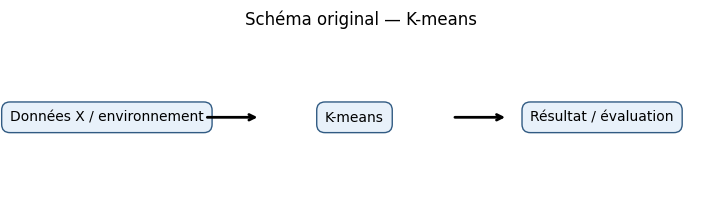

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'K-means'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — K-means', fontsize=12)
plt.show()


Silhouette: 0.5610505693103246


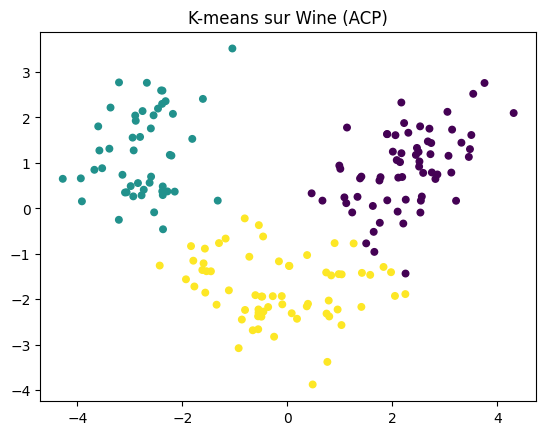

In [ ]:
from sklearn.cluster import KMeans
modele=KMeans(n_clusters=3,n_init=15,random_state=GRAINE).fit(X_clu)
print('Silhouette:',silhouette_score(X_clu,modele.labels_))
plt.scatter(X_clu[:,0],X_clu[:,1],c=modele.labels_,s=22);plt.title('K-means sur Wine (ACP)');plt.show()

### Présentation
**Classification hiérarchique (Hierarchical clustering)** — Famille : **clustering**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de clustering.
2. Intuition : fusion successive des groupes proches.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `Ward : minimiser l’augmentation de l’inertie intra-classe`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Dendrogramme lisible, pas de k initial.
11. Limites : Coûteux, sensible aux distances.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** segmentation de marchés.
- **Autre application :** classification de produits.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** silhouette, stabilité et interprétation.

**Réponse à la question ciblée :** Le dendrogramme montre l’ordre et la distance des fusions; Ward minimise la hausse de variance intra-groupe.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **n_clusters**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


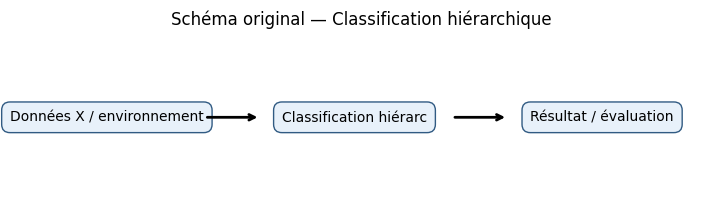

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Classification hiérarc'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Classification hiérarchique', fontsize=12)
plt.show()


In [ ]:
from sklearn.cluster import AgglomerativeClustering
etiquettes=AgglomerativeClustering(n_clusters=3,linkage='ward').fit_predict(X_clu)
print('Silhouette:',silhouette_score(X_clu,etiquettes))

Silhouette: 0.5590883962040383


### Présentation
**DBSCAN (Density-based spatial clustering)** — Famille : **clustering**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de clustering.
2. Intuition : formation de groupes denses à partir de eps et min_samples.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `|N_eps(x)| ≥ min_samples`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Détecte bruit et formes complexes.
11. Limites : Sensible à eps, densités variables difficiles.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** détection de zones de livraison.
- **Autre application :** analyse spatiale.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** silhouette, stabilité et interprétation.

**Réponse à la question ciblée :** Les points étiquetés −1 ne sont pas rattachés à une région suffisamment dense.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **eps, min_samples**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


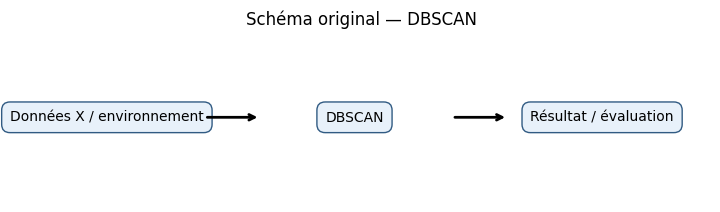

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'DBSCAN'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — DBSCAN', fontsize=12)
plt.show()


In [ ]:
from sklearn.cluster import DBSCAN
etiquettes=DBSCAN(eps=.7,min_samples=6).fit_predict(X_clu)
print('Groupes:',len(set(etiquettes)-{-1}),'Bruit:',int((etiquettes==-1).sum()))

Groupes: 2 Bruit: 8


### Présentation
**Mélanges gaussiens (Gaussian mixture model)** — Famille : **clustering**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de clustering.
2. Intuition : estimation probabiliste de plusieurs distributions.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `p(x)=Σₖπₖ N(x|μₖ,Σₖ)`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Appartenance souple, groupes elliptiques.
11. Limites : Hypothèse gaussienne, choix du nombre de composantes.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** segmentation probabiliste clients.
- **Autre application :** typologie biologique.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** silhouette, stabilité et interprétation.

**Réponse à la question ciblée :** Chaque observation reçoit une probabilité par groupe plutôt qu’une affectation exclusivement dure.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **n_components, random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


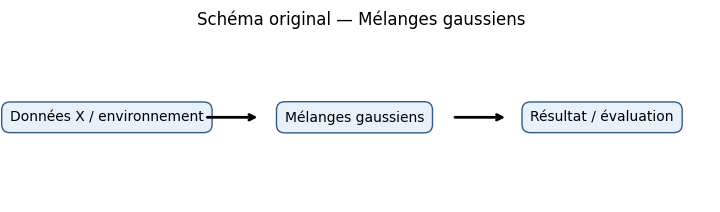

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Mélanges gaussiens'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Mélanges gaussiens', fontsize=12)
plt.show()


In [ ]:
from sklearn.mixture import GaussianMixture
modele=GaussianMixture(n_components=3,covariance_type='full',random_state=GRAINE).fit(X_clu)
etiquettes=modele.predict(X_clu)
print('Poids des groupes:',modele.weights_.round(3),'Silhouette:',silhouette_score(X_clu,etiquettes))

Poids des groupes: [0.38  0.269 0.351] Silhouette: 0.5591116207103001


### Présentation
**ACP (Principal component analysis)** — Famille : **réduction de dimension**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de réduction de dimension.
2. Intuition : projection sur les axes de variance maximale.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `variance expliquée = λⱼ/Σₖλₖ`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Rapide, synthèse des variables.
11. Limites : Axes parfois difficiles à interpréter, méthode linéaire.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** analyse de ratios financiers.
- **Autre application :** visualisation de vins.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** variance expliquée (ACP), conservation des voisinages.

**Réponse à la question ciblée :** La somme des variances expliquées des deux axes indique la part de variabilité conservée.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **n_components, random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


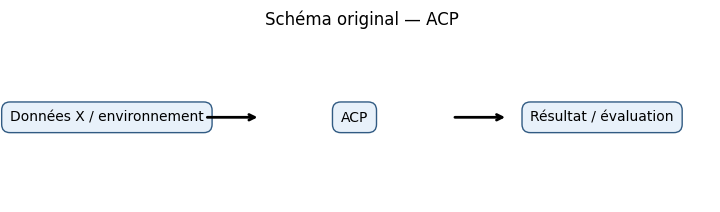

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'ACP'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — ACP', fontsize=12)
plt.show()


Variance expliquée: [0.12  0.096]


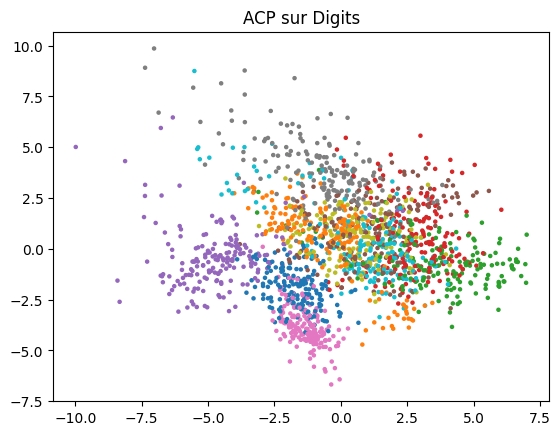

In [ ]:
from sklearn.decomposition import PCA
modele=PCA(n_components=2,random_state=GRAINE).fit(X_images)
projection=modele.transform(X_images)
print('Variance expliquée:',modele.explained_variance_ratio_.round(3))
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target,cmap='tab10',s=5);plt.title('ACP sur Digits');plt.show()

### Présentation
**t-SNE (t-distributed stochastic neighbor embedding)** — Famille : **réduction de dimension**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de réduction de dimension.
2. Intuition : préservation des voisinages locaux dans une carte.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `min KL(P||Q)`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Visualisation locale, structures non linéaires.
11. Limites : Distances globales trompeuses, coût élevé.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** visualisation de profils clients.
- **Autre application :** exploration d’images.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** variance expliquée (ACP), conservation des voisinages.

**Réponse à la question ciblée :** Les distances entre groupes éloignés ne représentent pas fidèlement les distances originales.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **n_components, perplexity, random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


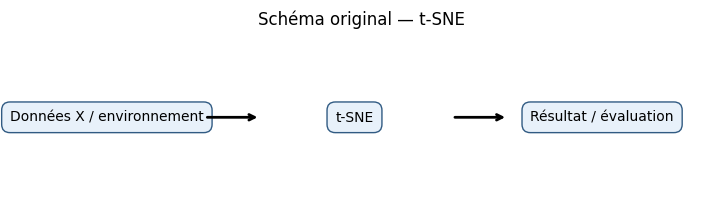

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 't-SNE'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — t-SNE', fontsize=12)
plt.show()


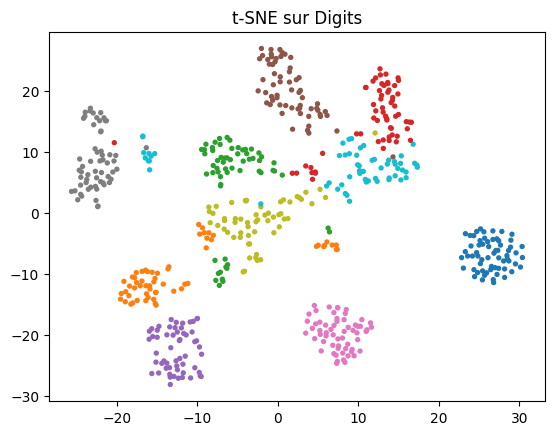

In [ ]:
from sklearn.manifold import TSNE
projection=TSNE(n_components=2,perplexity=35,random_state=GRAINE,init='pca').fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('t-SNE sur Digits');plt.show()

### Présentation
**UMAP (Uniform manifold approximation and projection)** — Famille : **réduction de dimension**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de réduction de dimension.
2. Intuition : construction puis projection d’un graphe de voisinage.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `min perte de correspondance des graphes`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Rapide, préserve des voisinages.
11. Limites : Résultat sensible aux paramètres, axes non interprétables.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** cartographie de clients.
- **Autre application :** visualisation de documents.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** variance expliquée (ACP), conservation des voisinages.

**Réponse à la question ciblée :** n_neighbors règle l’échelle locale/globale; min_dist contrôle la compacité des groupes.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **min_dist, n_components, n_neighbors, random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


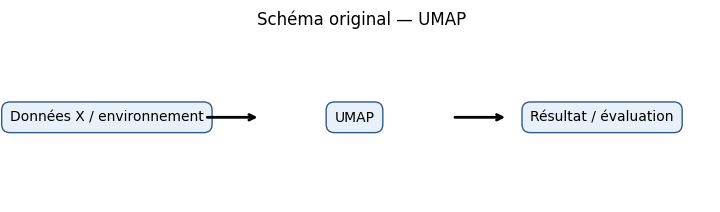

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'UMAP'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — UMAP', fontsize=12)
plt.show()


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


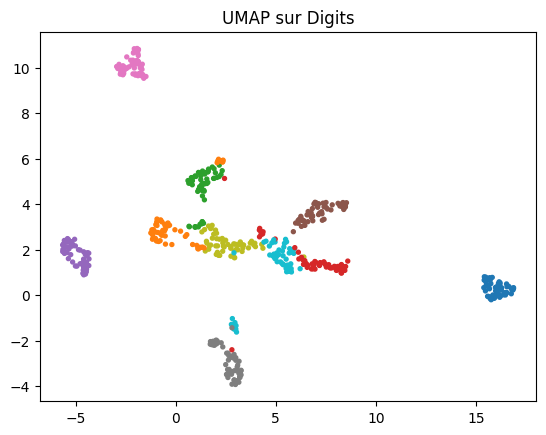

In [ ]:
import umap
projection=umap.UMAP(n_components=2,n_neighbors=20,min_dist=.15,random_state=GRAINE).fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('UMAP sur Digits');plt.show()

### Présentation
**Isolation Forest (Isolation forest)** — Famille : **détection d’anomalies**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de détection d’anomalies.
2. Intuition : isolement rapide des observations rares par divisions aléatoires.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `score ∝ 2^(−E[h(x)]/c(n))`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Rapide, sans étiquettes.
11. Limites : Alertes non nécessairement frauduleuses, seuil à choisir.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** transactions suspectes.
- **Autre application :** anomalies de capteurs.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** qualité des alertes, précision/rappel si étiquettes fiables.

**Réponse à la question ciblée :** Une observation rare peut être valide; une anomalie statistique ne prouve pas une erreur.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **contamination, n_estimators, random_state**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


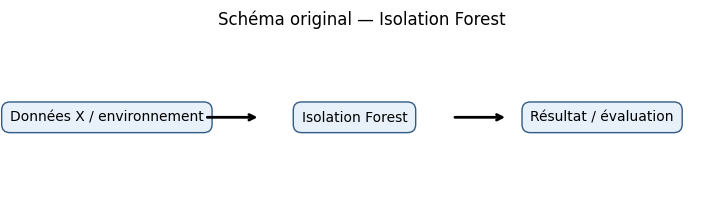

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Isolation Forest'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Isolation Forest', fontsize=12)
plt.show()


In [ ]:
from sklearn.ensemble import IsolationForest
# Recherche d'observations atypiques dans les caractéristiques de vins (sans ajouter de faux points)
modele=IsolationForest(contamination=.05,n_estimators=150,random_state=GRAINE).fit(X_clu)
indices=np.where(modele.predict(X_clu)==-1)[0]
print('Nombre de vins atypiques:',len(indices),'Indices (extrait):',indices[:12])

Nombre de vins atypiques: 9 Indices (extrait): [  3  14  18  59  80 115 146 158 177]


### Présentation
**Bandits manchots (Multi-armed bandits)** — Famille : **renforcement**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de renforcement.
2. Intuition : choix répété d’actions et observation des gains.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `Q̂(a)=Σₜ:rₜ pour a / N(a)`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Apprentissage en ligne, adaptation.
11. Limites : Exploration coûteuse, contexte parfois ignoré.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** choix de publicités.
- **Autre application :** optimisation d’offres.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** récompense cumulée, réussite, variabilité entre graines.

**Réponse à la question ciblée :** Le gain moyen estimé est la somme des récompenses observées pour un bras divisée par son nombre de tirages.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **paramètres par défaut ou paramètres définis dans la cellule**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


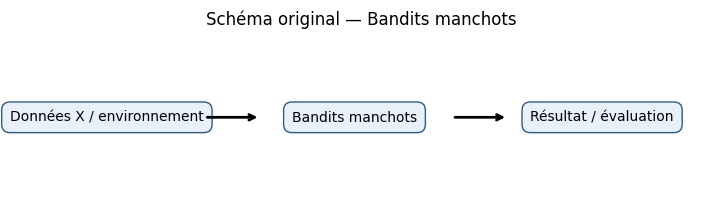

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Bandits manchots'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Bandits manchots', fontsize=12)
plt.show()


In [ ]:
# Bandit simulé à 4 choix : la politique choisit successivement chaque bras
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int)
for t in range(800):
    bras=t%4
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Probabilités estimées:',(sommes/comptes).round(3))

Probabilités estimées: [0.205 0.335 0.605 0.765]


### Présentation
**Epsilon-greedy (Epsilon-greedy policy)** — Famille : **renforcement**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de renforcement.
2. Intuition : exploration aléatoire avec probabilité epsilon.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `a=aléatoire avec probabilité ε; sinon argmax Q̂(a)`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Simple, contrôle exploration.
11. Limites : Exploration uniforme inefficace, ε à régler.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** tests de promotions.
- **Autre application :** choix de recommandations.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** récompense cumulée, réussite, variabilité entre graines.

**Réponse à la question ciblée :** Explorer consiste à tester au hasard; exploiter consiste à choisir le meilleur bras estimé.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **epsilon**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


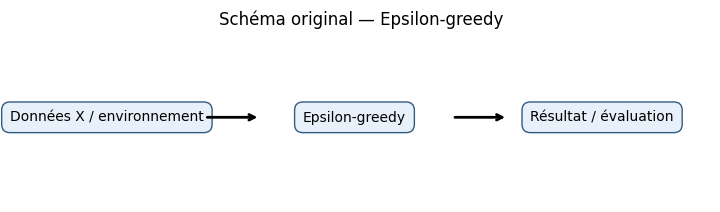

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Epsilon-greedy'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Epsilon-greedy', fontsize=12)
plt.show()


In [ ]:
# Epsilon-greedy sur les mêmes 4 bras simulés
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int);epsilon=.15
for t in range(1200):
    bras=int(generateur.integers(4)) if generateur.random()<epsilon else int(np.argmax((sommes+1)/(comptes+2)))
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Nombre de choix:',comptes,'Estimations:',(sommes/np.maximum(comptes,1)).round(3))

Nombre de choix: [  55   53   44 1048] Estimations: [0.182 0.377 0.614 0.751]


### Présentation
**Q-learning (Q-learning)** — Famille : **renforcement**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de renforcement.
2. Intuition : mise à jour hors politique par la meilleure action future.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `Q(s,a)←Q(s,a)+α[r+γmaxₐ′Q(s′,a′)−Q(s,a)]`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Apprend politique optimale tabulaire, simple.
11. Limites : Grandes tables impossibles, exploration nécessaire.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** optimisation de stock simplifiée.
- **Autre application :** navigation Taxi.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** récompense cumulée, réussite, variabilité entre graines.

**Réponse à la question ciblée :** Le max représente la meilleure valeur future estimée, indépendamment de l’action effectivement choisie.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **epsilon**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


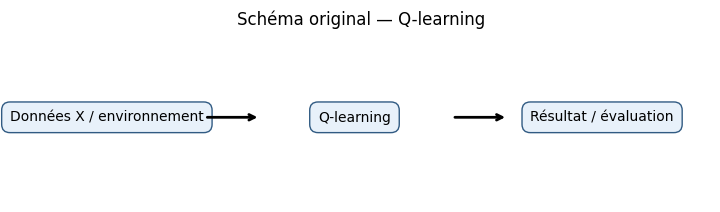

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'Q-learning'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — Q-learning', fontsize=12)
plt.show()


In [ ]:
# Q-learning manuel sur Taxi-v3 : exploration epsilon-greedy
import gymnasium as gym
env=gym.make('Taxi-v3');Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400)
    for pas in range(200):
        action=int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
        suivant,recompense,termine,tronque,_=env.step(action)
        cible=recompense+(0 if termine else .96*np.max(Q[suivant]))
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat=suivant
        if termine or tronque:break
print('Q-learning Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2));env.close()

/usr/local/lib/python3.13/dist-packages/gymnasium/envs/registration.py:511: DeprecationWarning: WARN: The environment Taxi-v3 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


DeprecatedEnv: Environment version v3 for `Taxi` is deprecated. Please use `Taxi-v4` instead.

### Présentation
**SARSA (State-action-reward-state-action)** — Famille : **renforcement**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de renforcement.
2. Intuition : mise à jour suivant l’action réellement sélectionnée.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `Q(s,a)←Q(s,a)+α[r+γQ(s′,a′)−Q(s,a)]`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Prend en compte la politique exploratoire, simple.
11. Limites : Sensible à la politique, tables volumineuses.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** gestion de ressources simulée.
- **Autre application :** navigation Taxi.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** récompense cumulée, réussite, variabilité entre graines.

**Réponse à la question ciblée :** SARSA est on-policy : la cible utilise la prochaine action réellement choisie par la politique.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **epsilon**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'SARSA'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — SARSA', fontsize=12)
plt.show()


In [ ]:
# SARSA manuel sur Taxi-v3 (on-policy)
import gymnasium as gym
env=gym.make('Taxi-v3');Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
def choisir_action(etat,epsilon):
    return int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400);action=choisir_action(etat,epsilon)
    for pas in range(200):
        suivant,recompense,termine,tronque,_=env.step(action)
        action_suiv=choisir_action(suivant,epsilon)
        cible=recompense+(0 if termine else .96*Q[suivant,action_suiv])
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat,action=suivant,action_suiv
        if termine or tronque:break
print('SARSA Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2));env.close()

### Présentation
**DQN — cible conceptuelle (Deep Q-network)** — Famille : **renforcement**.

1. Objectif : produire une estimation, une structure ou une décision adaptée à la tâche de renforcement.
2. Intuition : approximation des valeurs Q par réseau de neurones.
3. Entrées : matrice de caractéristiques `X` et, si l’apprentissage est supervisé, cible `y`.
4. Étape de calcul : ajustement des paramètres internes sur les données disponibles.
5. Sortie : prédictions, groupes, coordonnées, scores ou actions selon le modèle.
6. Critère essentiel : `L(θ)=E[(r+γmaxₐ′Q(s′,a′;θ⁻)−Q(s,a;θ))²]`.
7. Notation : `x` désigne une observation, `y` sa cible, `ŷ` une prédiction, `Σ` une somme, `Q` une valeur d'action, `r` une récompense, et `t` ou `i` un indice. Les autres lettres sont précisées par le contexte du modèle.
8. Paramètres appris : coefficients, seuils, centres, poids ou valeurs Q selon la méthode.
9. Hyperparamètres : réglages fixés avant l'ajustement, par exemple la complexité, la pénalité ou le taux d'apprentissage.
10. Avantages : Gère grands états, apprend des représentations.
11. Limites : Entraînement instable, coûteux.

### Schéma explicatif
Le schéma original généré par la cellule suivante montre le chemin **données → calcul/apprentissage → résultat**. Les flèches indiquent le sens du traitement; elles ne constituent pas une mesure de performance.

### Contextes d'utilisation
- **Gestion/finance/marketing/logistique :** pilotage de stocks en simulation.
- **Autre application :** contrôle de jeux.
- **Données et prérequis :** observations représentatives, variables numériques ou encodées, traitement des manquants et normalisation si les distances ou la régularisation l'exigent. Pour le renforcement, utiliser un environnement interactif, des états, actions et récompenses.
- **Cas peu approprié :** lorsque les hypothèses de la méthode ne correspondent pas à la structure des données ou que les ressources nécessaires dépassent les moyens disponibles.
- **Évaluation :** récompense cumulée, réussite, variabilité entre graines.

**Réponse à la question ciblée :** Le réseau cible stabilise la cible de Bellman; le replay casse la corrélation temporelle des transitions.

### Analyse de l'expérience Python
Le code fourni prépare ou réutilise les données du notebook, instancie la méthode puis exécute le calcul. Les réglages explicitement visibles comprennent : **gamma**. La sortie exacte doit être lue après exécution de la cellule d'origine : elle n'est pas inventée ici. Une métrique calculée sur un seul découpage ne démontre ni robustesse ni causalité; une visualisation ne prouve pas la qualité prédictive. Les données scikit-learn intégrées sont des jeux publics réels; les tirages aléatoires ou les trajectoires Gymnasium sont à distinguer des observations réelles.


In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
for x, titre in [(0.1, 'Données X / environnement'), (3.65, 'DQN — cible conceptuel'), (7.2, 'Résultat / évaluation')]:
    ax.text(x+1.25, 1, titre, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e8f1fa', edgecolor='#315b83'))
for x in (2.75, 6.3):
    ax.annotate('', xy=(x+.8,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_title('Schéma original — DQN — cible conceptuelle', fontsize=12)
plt.show()


In [ ]:
# DQN : calcul pédagogique d'une cible de Bellman (aucun réseau entraîné)
recompenses=np.array([2.,-1.,10.,0.]);termine=np.array([False,False,True,False])
q_cible_etat_suivant=np.array([5.,3.,7.,2.]);gamma=.9
cibles=recompenses+gamma*(~termine)*q_cible_etat_suivant
print('Cibles DQN conceptuelles:',cibles)
# Un DQN complet utiliserait un réseau en ligne, un réseau cible et un replay buffer.

## Partie B — Comparaison reproductible sur données publiques réelles
**Sources :** `load_diabetes` (442 observations, 10 variables, cible quantitative), `load_breast_cancer` (569 observations, 30 variables, cible binaire), `load_wine` (178 observations, 13 variables, étiquettes de cépages) et `load_digits` (1 797 observations, 64 pixels, classes 0–9). Organisme : scikit-learn (données originales documentées dans les descriptions `DESCR`). Documentation : https://scikit-learn.org/stable/datasets/toy_dataset.html ; licence et provenance spécifiques : consulter `jeu_reg.DESCR`, `jeu_cls.DESCR`, `jeu_groupes.DESCR` et `jeu_images.DESCR`. Date de consultation à renseigner lors de l'exécution. Les données sont publiques et non synthétiques.

Le tableau suivant compare des méthodes sur le même découpage de test; pour une étude rigoureuse, ajouter un ensemble de validation ou une validation croisée **sur l'entraînement seulement**, et réserver le test à l'évaluation finale. Les modèles de renforcement ne se comparent pas à ces CSV : utiliser les épisodes Gymnasium et comparer récompenses et réussites entre graines.


In [ ]:
import sklearn, numpy as np, pandas as pd
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, precision_score, recall_score, f1_score, roc_auc_score
print('Versions : scikit-learn', sklearn.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
resultats=[]
for nom, mod in [('Linéaire',LinearRegression()), ('Ridge',Ridge(alpha=1.0)), ('Forêt aléatoire',RandomForestRegressor(n_estimators=100,random_state=42))]:
    mod.fit(Xr_ent,yr_ent); p=mod.predict(Xr_test)
    resultats.append([nom,mean_absolute_error(yr_test,p),np.sqrt(mean_squared_error(yr_test,p)),r2_score(yr_test,p)])
display(pd.DataFrame(resultats,columns=['Modèle','MAE','RMSE','R²']))
resultats=[]
for nom,mod in [('Logistique',make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000))),('Forêt aléatoire',RandomForestClassifier(n_estimators=100,random_state=42))]:
    mod.fit(Xc_ent,yc_ent); p=mod.predict(Xc_test); prob=mod.predict_proba(Xc_test)[:,1]
    resultats.append([nom,precision_score(yc_test,p),recall_score(yc_test,p),f1_score(yc_test,p),roc_auc_score(yc_test,prob)])
display(pd.DataFrame(resultats,columns=['Modèle','Précision','Rappel','F1','ROC-AUC']))


## Annexes — Implémentations manuelles (Partie B)

Reproduire les principes de la descente de gradient et de K-means sans utiliser leurs estimateurs prédéfinis. Comparer les résultats aux références scikit-learn.

In [ ]:
# Descente de gradient manuelle pour une régression linéaire sur Diabetes, avec 1 variable
x=X_reg[:,2].copy();x=(x-x.mean())/x.std();y=y_reg.copy()
poids=0.;biais=y.mean();pas=.015
for iteration in range(3000):
    erreur=poids*x+biais-y
    poids-=pas*2*np.mean(erreur*x)
    biais-=pas*2*np.mean(erreur)
print('Manuel:',round(poids,3),round(biais,3))
from sklearn.linear_model import LinearRegression
modele_ref=LinearRegression().fit(x.reshape(-1,1),y)
print('Scikit-learn:',modele_ref.coef_.round(3),round(modele_ref.intercept_,3))

In [ ]:
# K-means manuel sur la projection Wine, avec centroïdes et inertie
valeurs=X_clu.copy();k=3;generateur=np.random.default_rng(GRAINE)
centroides=valeurs[generateur.choice(len(valeurs),size=k,replace=False)].copy()
for iteration in range(100):
    distances=((valeurs[:,None,:]-centroides[None,:,:])**2).sum(axis=2)
    groupes=distances.argmin(axis=1)
    nouveaux=np.array([valeurs[groupes==j].mean(axis=0) if np.any(groupes==j) else centroides[j] for j in range(k)])
    if np.allclose(nouveaux,centroides):break
    centroides=nouveaux
inertie=np.sum((valeurs-centroides[groupes])**2)
from sklearn.cluster import KMeans
reference=KMeans(n_clusters=k,n_init=15,random_state=GRAINE).fit(valeurs)
print('Inertie manuelle:',round(inertie,2),'Inertie sklearn:',round(reference.inertia_,2))
# Attention : K-means est sensible à l'initialisation ; les deux inerties peuvent différer.

Le **Q-learning tabulaire manuel** est présenté à la section 27 sur Taxi-v3, et **SARSA** à la section 28. Scikit-learn ne propose pas de Q-learning tabulaire équivalent. Comparer plutôt les deux méthodes avec les mêmes paramètres, graines, nombre d’épisodes et métriques de succès.